- Hvor mye bedre kan vi predikere strømforbruk når vi bruker historisk forbruk i tillegg til kalenderinformasjon?
- Hvilken modell gir de beste prognosene på nye data?

In [1]:
import pandas as pd
import numpy as np

# Kalenderbaserte features

In [2]:
df = pd.read_csv(
    "../data/consumption_selected.csv",
    sep=";",
    decimal=","
)

# Kalenderbaserte features
df["HOUR_SIN"] = np.sin(2 * np.pi * df["HOUR"] / 24)
df["HOUR_COS"] = np.cos(2 * np.pi * df["HOUR"] / 24)

df["MONTH_SIN"] = np.sin(2 * np.pi * (df["MONTH"] - 1) / 12)
df["MONTH_COS"] = np.cos(2 * np.pi * (df["MONTH"] - 1) / 12)

df["DAY_SIN"] = np.sin(2 * np.pi * df["DAY_OF_WEEK"] / 7)
df["DAY_COS"] = np.cos(2 * np.pi * df["DAY_OF_WEEK"] / 7)

df["IS_WEEKEND"] = (df["DAY_OF_WEEK"] >= 5).astype(int)

calendar_features = [
    "HOUR_SIN", "HOUR_COS",
    "MONTH_SIN", "MONTH_COS",
    "DAY_SIN", "DAY_COS",
    "IS_WEEKEND",
    "KOMMUNE",
    "FORBRUKSGRUPPE"
]

print(df[calendar_features].head())

   HOUR_SIN  HOUR_COS  MONTH_SIN  MONTH_COS   DAY_SIN  DAY_COS  IS_WEEKEND  \
0       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   
1       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   
2       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   
3       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   
4       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   

  KOMMUNE FORBRUKSGRUPPE  
0    Alta     Forretning  
1    Alta       Industri  
2    Alta         Privat  
3  Bergen     Forretning  
4  Bergen       Industri  


Gjør dette slik at tallene blir mer som en klokke

# Historiske prediktorene

In [3]:
# Parse tidspunktene til norsk lokal tid
df["TIMESTAMP"] = (
    pd.to_datetime(df["STARTTID"], utc=True)
      .dt.tz_convert("Europe/Oslo")
)

df["DATE"] = df["TIMESTAMP"].dt.date
df["LOCAL_HOUR"] = df["TIMESTAMP"].dt.hour

keys = ["KOMMUNE", "FORBRUKSGRUPPE"]

# Daglige gjennomsnitt
daily = (
    df.groupby(keys + ["DATE"])["VOLUM_KWH"]
      .mean()
      .reset_index(name="DAILY_MEAN")
)

# Lag hjelpekolonne med dato
df["DATE_KEY"] = (
    df["TIMESTAMP"]
    .dt.tz_localize(None)
    .dt.normalize()
)

daily["DATE_KEY"] = pd.to_datetime(daily["DATE"])

# Gjennomsnitt to kalenderdøgn tidligere
previous = daily[keys + ["DATE_KEY", "DAILY_MEAN"]].copy()
previous["DATE_KEY"] += pd.Timedelta(days=2)
previous = previous.rename(
    columns={"DAILY_MEAN": "PREV_DAY_MEAN"}
)

df = df.merge(
    previous,
    on=keys + ["DATE_KEY"],
    how="left",
    validate="many_to_one"
)

# Timeforbruk 2 og 7 kalenderdøgn tidligere
for days in [2, 7]:
    history = df[
        keys + ["DATE_KEY", "LOCAL_HOUR", "VOLUM_KWH"]
    ].copy()

    history["DATE_KEY"] += pd.Timedelta(days=days)
    history = history.rename(
        columns={"VOLUM_KWH": f"LAG_{days}D"}
    )

    # Unngå mange-til-mange-merge ved gjentatt time
    # under overgang til vintertid
    history = (
        history.groupby(
            keys + ["DATE_KEY", "LOCAL_HOUR"],
            as_index=False
        )[f"LAG_{days}D"].mean()
    )

    df = df.merge(
        history,
        on=keys + ["DATE_KEY", "LOCAL_HOUR"],
        how="left",
        validate="many_to_one"
    )

print(
    df[[
        "KOMMUNE", "FORBRUKSGRUPPE",
        "DATE_KEY", "LOCAL_HOUR",
        "VOLUM_KWH", "LAG_2D",
        "LAG_7D", "PREV_DAY_MEAN"
    ]].tail(10)
)

           KOMMUNE FORBRUKSGRUPPE   DATE_KEY  LOCAL_HOUR   VOLUM_KWH  \
1115960    Sunndal         Privat 2026-04-30          23    5328.694   
1115961     Tromsø     Forretning 2026-04-30          23   40554.563   
1115962     Tromsø       Industri 2026-04-30          23    9426.388   
1115963     Tromsø         Privat 2026-04-30          23   80151.881   
1115964  Trondheim     Forretning 2026-04-30          23   74044.931   
1115965  Trondheim       Industri 2026-04-30          23   38626.449   
1115966  Trondheim         Privat 2026-04-30          23  144997.318   
1115967      Årdal     Forretning 2026-04-30          23    1619.537   
1115968      Årdal       Industri 2026-04-30          23  390816.464   
1115969      Årdal         Privat 2026-04-30          23    4130.784   

             LAG_2D      LAG_7D  PREV_DAY_MEAN  
1115960    6194.545    6372.506    6024.442542  
1115961   44391.189   49477.595   55348.055250  
1115962   10542.804   10054.141   12342.449875  
1115963   8

DAILY_MEAN = Hvordan var hele dagen for 2 dager siden?
LAG_2D = Hva var forbruket på samme time 2 dager siden?
LAG_7D = Hva var forbruket på samme time 1 uke siden?

For å gi modellen historikk slik at den lettere kan oppdage mønstre og lage bedre prognoser.

# Kontroll

In [4]:
lag_features = [
    "LAG_2D",
    "LAG_7D",
    "PREV_DAY_MEAN"
]

print("Antall observasjoner:", len(df))

print("\nManglende historiske verdier:")
print(df[lag_features].isna().sum())

print("\nAndel manglende (%):")
print(
    (df[lag_features].isna().mean() * 100).round(2)
)

print("\nDuplikater per kommune, gruppe og tidspunkt:")
print(
    df.duplicated(
        subset=["KOMMUNE", "FORBRUKSGRUPPE", "TIMESTAMP"]
    ).sum()
)

Antall observasjoner: 1115970

Manglende historiske verdier:
LAG_2D           1590
LAG_7D           5190
PREV_DAY_MEAN    1440
dtype: int64

Andel manglende (%):
LAG_2D           0.14
LAG_7D           0.47
PREV_DAY_MEAN    0.13
dtype: float64

Duplikater per kommune, gruppe og tidspunkt:
0


In [5]:
lag_features = [
    "LAG_2D",
    "LAG_7D",
    "PREV_DAY_MEAN"
]

# Finn observasjoner som mangler minst én lag feature
missing = df[df[lag_features].isna().any(axis=1)]

print("Manglende observasjoner per år:")
print(missing.groupby("YEAR").size())

print("\nManglende observasjoner per kommune:")
print(
    missing.groupby("KOMMUNE")
    .size()
    .sort_values(ascending=False)
)

print("\nAntall komplette observasjoner:")
print(df.dropna(subset=lag_features).shape[0])

Manglende observasjoner per år:
YEAR
2022    5100
2023      60
2024      60
2025      60
2026      60
dtype: int64

Manglende observasjoner per kommune:
KOMMUNE
Alta            534
Bergen          534
Bodø            534
Kristiansand    534
Oslo            534
Stavanger       534
Sunndal         534
Tromsø          534
Trondheim       534
Årdal           534
dtype: int64

Antall komplette observasjoner:
1110630


In [6]:
missing_dates = (
    df.loc[df[lag_features].isna().any(axis=1)]
      .groupby("DATE_KEY")
      .size()
)

print(missing_dates.to_string())


DATE_KEY
2022-02-01    720
2022-02-02    720
2022-02-03    720
2022-02-04    720
2022-02-05    720
2022-02-06    720
2022-02-07    720
2022-03-29     30
2022-04-03     30
2023-03-28     30
2023-04-02     30
2024-04-02     30
2024-04-07     30
2025-04-01     30
2025-04-06     30
2026-03-31     30
2026-04-05     30


Data som magler kommer av at vi ser tilbake i tid og sommertid

# Fjerner observasjoner med manglende historikk

In [7]:
# Fjern observasjoner med manglende historiske prediktorer
df_model = df.dropna(subset=lag_features).copy()

# Kontroller resultatet
print("Før:", len(df))
print("Etter:", len(df_model))
print("Fjernet:", len(df) - len(df_model))

print("\nManglende historiske verdier:")
print(df_model[lag_features].isna().sum())

Før: 1115970
Etter: 1110630
Fjernet: 5340

Manglende historiske verdier:
LAG_2D           0
LAG_7D           0
PREV_DAY_MEAN    0
dtype: int64


# Train / Validation / Test Split

In [8]:
# Train: 2022–2024
train = df_model[df_model["YEAR"] <= 2024].copy()

# Validation: 2025
validation = df_model[df_model["YEAR"] == 2025].copy()

# Test: 2026
test = df_model[df_model["YEAR"] == 2026].copy()

# Kontroller oppdelingen
for name, subset in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(
        f"{name}: {len(subset):,} observasjoner | "
        f"{subset['DATE_KEY'].min().date()} "
        f"til {subset['DATE_KEY'].max().date()}"
    )

print("\nTotalt:", len(train) + len(validation) + len(test))

Train: 761,580 observasjoner | 2022-02-08 til 2024-12-31
Validation: 262,740 observasjoner | 2025-01-01 til 2025-12-31
Test: 86,310 observasjoner | 2026-01-01 til 2026-04-30

Totalt: 1110630


In [9]:
# Modell A: Kun kalenderbaserte prediktorer
features_A = calendar_features.copy()

# Modell B: Kalender + historisk strømforbruk
features_B = calendar_features + lag_features

target = "VOLUM_KWH"

print("Modell A:", features_A)
print("\nModell B:", features_B)

Modell A: ['HOUR_SIN', 'HOUR_COS', 'MONTH_SIN', 'MONTH_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND', 'KOMMUNE', 'FORBRUKSGRUPPE']

Modell B: ['HOUR_SIN', 'HOUR_COS', 'MONTH_SIN', 'MONTH_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND', 'KOMMUNE', 'FORBRUKSGRUPPE', 'LAG_2D', 'LAG_7D', 'PREV_DAY_MEAN']


A bruker kalender, kommune og forbruksgruppe.

B bruker det samme, pluss de tre historiske variablene.

In [10]:
# Modell A
X_train_A = train[features_A].copy()
X_val_A = validation[features_A].copy()
X_test_A = test[features_A].copy()

# Modell B
X_train_B = train[features_B].copy()
X_val_B = validation[features_B].copy()
X_test_B = test[features_B].copy()

# Samme target for begge modellene
y_train = train[target].copy()
y_val = validation[target].copy()
y_test = test[target].copy()

print("Modell A:", X_train_A.shape)
print("Modell B:", X_train_B.shape)
print("Target:", y_train.shape)

Modell A: (761580, 9)
Modell B: (761580, 12)
Target: (761580,)


Preprocessing

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kategoriske prediktorer
categorical_features = [
    "KOMMUNE",
    "FORBRUKSGRUPPE"
]

# Numeriske prediktorer for hver modell
numerical_A = [
    col for col in features_A
    if col not in categorical_features
]

numerical_B = [
    col for col in features_B
    if col not in categorical_features
]

# Preprocessing for Modell A
preprocessor_A = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_A),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Preprocessing for Modell B
preprocessor_B = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_B),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

print("Numeriske variabler A:", numerical_A)
print("Numeriske variabler B:", numerical_B)
print("\nPreprocessing opprettet.")

Numeriske variabler A: ['HOUR_SIN', 'HOUR_COS', 'MONTH_SIN', 'MONTH_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND']
Numeriske variabler B: ['HOUR_SIN', 'HOUR_COS', 'MONTH_SIN', 'MONTH_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND', 'LAG_2D', 'LAG_7D', 'PREV_DAY_MEAN']

Preprocessing opprettet.


Gjør kategorier om til tall og skalerer de

# Baseline A

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Gjennomsnitt fra treningsdataene
baseline_A = (
    train.groupby([
        "KOMMUNE",
        "FORBRUKSGRUPPE",
        "DAY_OF_WEEK",
        "HOUR"
    ])["VOLUM_KWH"]
    .mean()
    .rename("PREDICTION")
    .reset_index()
)

# Koble prediksjonene til valideringsdataene
val_baseline_A = validation.merge(
    baseline_A,
    on=["KOMMUNE", "FORBRUKSGRUPPE", "DAY_OF_WEEK", "HOUR"],
    how="left",
    validate="many_to_one"
)

# Kontroller at alle observasjoner fikk prediksjon
print("Manglende prediksjoner:",
      val_baseline_A["PREDICTION"].isna().sum())

# Evaluer
y_pred_A = val_baseline_A["PREDICTION"]

mae_A = mean_absolute_error(y_val, y_pred_A)
rmse_A = np.sqrt(mean_squared_error(y_val, y_pred_A))

print(f"Baseline A - MAE: {mae_A:,.2f} kWh")
print(f"Baseline A - RMSE: {rmse_A:,.2f} kWh")

Manglende prediksjoner: 0
Baseline A - MAE: 20,365.13 kWh
Baseline A - RMSE: 40,934.72 kWh


Baseline B

In [13]:
# Prediksjon = forbruk samme time uken før
y_pred_B = validation["LAG_7D"]

mae_B = mean_absolute_error(y_val, y_pred_B)
rmse_B = np.sqrt(mean_squared_error(y_val, y_pred_B))

print(f"Baseline B - MAE: {mae_B:,.2f} kWh")
print(f"Baseline B - RMSE: {rmse_B:,.2f} kWh")

Baseline B - MAE: 9,248.14 kWh
Baseline B - RMSE: 21,594.34 kWh


Opprette modell

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Modell A: Kalenderbaserte prediktorer
model_A = Pipeline([
    ("preprocessing", preprocessor_A),
    ("regression", LinearRegression())
])

# Modell B: Kalender + historisk forbruk
model_B = Pipeline([
    ("preprocessing", preprocessor_B),
    ("regression", LinearRegression())
])

print("Begge regresjonsmodellene er opprettet.")

Begge regresjonsmodellene er opprettet.


Trainig

In [15]:
# Tren Modell A
model_A.fit(X_train_A, y_train)

# Tren Modell B
model_B.fit(X_train_B, y_train)

print("Begge modellene er ferdig trent.")

Begge modellene er ferdig trent.


Evaluering på valideringsdata

In [16]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Prediksjoner på valideringsdata
pred_A = model_A.predict(X_val_A)
pred_B = model_B.predict(X_val_B)

# Sammenlign modellene
results = pd.DataFrame({
    "Model": ["Linear Regression A", "Linear Regression B"],
    "MAE": [
        mean_absolute_error(y_val, pred_A),
        mean_absolute_error(y_val, pred_B)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, pred_A)),
        np.sqrt(mean_squared_error(y_val, pred_B))
    ],
    "R2": [
        r2_score(y_val, pred_A),
        r2_score(y_val, pred_B)
    ]
})

print(results.round(3).to_string(index=False))

              Model       MAE       RMSE    R2
Linear Regression A 89738.787 133348.066 0.339
Linear Regression B  8492.746  17740.566 0.988


Undersøkelse av den store diffen

In [17]:
# Sammenlign lineær regresjon B med historisk baseline

comparison = pd.DataFrame({
    "Model": [
        "Baseline B (LAG_7D)",
        "Linear Regression B"
    ],
    "MAE": [
        mean_absolute_error(y_val, validation["LAG_7D"]),
        mean_absolute_error(y_val, pred_B)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, validation["LAG_7D"])),
        np.sqrt(mean_squared_error(y_val, pred_B))
    ],
    "R2": [
        r2_score(y_val, validation["LAG_7D"]),
        r2_score(y_val, pred_B)
    ]
})

print(comparison.round(3).to_string(index=False))


              Model      MAE      RMSE    R2
Baseline B (LAG_7D) 9248.137 21594.339 0.983
Linear Regression B 8492.746 17740.566 0.988


Evaluering av modellene per forbruksgruppe

In [18]:
# Lag evalueringsdatasett
evaluation = validation[
    ["KOMMUNE", "FORBRUKSGRUPPE", "VOLUM_KWH", "LAG_7D"]
].copy()

evaluation["PRED_A"] = pred_A
evaluation["PRED_B"] = pred_B

# Evaluer per forbruksgruppe
group_results = []

for group, subset in evaluation.groupby("FORBRUKSGRUPPE"):
    actual = subset["VOLUM_KWH"]

    for model_name, prediction in [
        ("Baseline B", subset["LAG_7D"]),
        ("Linear Regression A", subset["PRED_A"]),
        ("Linear Regression B", subset["PRED_B"])
    ]:
        group_results.append({
            "Group": group,
            "Model": model_name,
            "MAE": mean_absolute_error(actual, prediction),
            "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
            "R2": r2_score(actual, prediction)
        })

group_results = pd.DataFrame(group_results)

print(
    group_results
    .sort_values(["Group", "MAE"])
    .round(3)
    .to_string(index=False)
)


     Group               Model        MAE       RMSE    R2
Forretning          Baseline B   6434.483  14639.384 0.984
Forretning Linear Regression B   7737.454  16127.938 0.981
Forretning Linear Regression A  61145.545  89178.904 0.420
  Industri Linear Regression B   7053.453  16586.028 0.994
  Industri          Baseline B   7839.892  20876.715 0.990
  Industri Linear Regression A 131886.875 180981.797 0.281
    Privat Linear Regression B  10687.330  20223.163 0.979
    Privat          Baseline B  13470.035  27364.168 0.962
    Privat Linear Regression A  76183.940 112418.112 0.362


Ridge Regression

In [19]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

# Ridge-modell med samme preprocessing som tidligere
ridge_B = Pipeline([
    ("preprocessing", preprocessor_B),
    ("regression", Ridge(alpha=1.0))
])

# Tren på 2022–2024
ridge_B.fit(X_train_B, y_train)

# Prediker 2025
pred_ridge_B = ridge_B.predict(X_val_B)

# Evaluer
print("Ridge B")
print(
    "MAE:",
    round(mean_absolute_error(y_val, pred_ridge_B), 3)
)
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_val, pred_ridge_B)), 3)
)
print(
    "R2:",
    round(r2_score(y_val, pred_ridge_B), 3)
)

Ridge B
MAE: 8492.784
RMSE: 17740.551
R2: 0.988


Random Forest

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Preprocessing uten skalering
rf_preprocessor_B = ColumnTransformer([
    ("num", "passthrough", numerical_B),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Random Forest
rf_B = Pipeline([
    ("preprocessing", rf_preprocessor_B),
    ("regression", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest B opprettet.")

Random Forest B opprettet.


Trening og evaluring

In [21]:
# Tren modellen på 2022–2024
rf_B.fit(X_train_B, y_train)

# Prediker på 2025
pred_rf_B = rf_B.predict(X_val_B)

# Evaluer
print("Random Forest B")
print("MAE:", round(mean_absolute_error(y_val, pred_rf_B), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, pred_rf_B)), 3))
print("R2:", round(r2_score(y_val, pred_rf_B), 3))

Random Forest B
MAE: 6466.854
RMSE: 14691.663
R2: 0.992


Evaluer Random Forest per forbruksgruppe

In [22]:
# Legg til Random Forest-prediksjonene
evaluation["PRED_RF_B"] = pred_rf_B

# Sammenlign modellene per forbruksgruppe
rf_group_results = []

for group, subset in evaluation.groupby("FORBRUKSGRUPPE"):
    actual = subset["VOLUM_KWH"]

    for model_name, prediction in [
        ("Baseline B", subset["LAG_7D"]),
        ("Linear Regression B", subset["PRED_B"]),
        ("Random Forest B", subset["PRED_RF_B"])
    ]:
        rf_group_results.append({
            "Group": group,
            "Model": model_name,
            "MAE": mean_absolute_error(actual, prediction),
            "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
            "R2": r2_score(actual, prediction)
        })

rf_group_results = pd.DataFrame(rf_group_results)

print(
    rf_group_results
    .sort_values(["Group", "MAE"])
    .round(3)
    .to_string(index=False)
)

     Group               Model       MAE      RMSE    R2
Forretning     Random Forest B  4658.486 10535.540 0.992
Forretning          Baseline B  6434.483 14639.384 0.984
Forretning Linear Regression B  7737.454 16127.938 0.981
  Industri     Random Forest B  6085.915 15489.904 0.995
  Industri Linear Regression B  7053.453 16586.028 0.994
  Industri          Baseline B  7839.892 20876.715 0.990
    Privat     Random Forest B  8656.163 17222.083 0.985
    Privat Linear Regression B 10687.330 20223.163 0.979
    Privat          Baseline B 13470.035 27364.168 0.962


Random Forest A

In [23]:
# Preprocessing for Random Forest A
rf_preprocessor_A = ColumnTransformer([
    ("num", "passthrough", numerical_A),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Random Forest A
rf_A = Pipeline([
    ("preprocessing", rf_preprocessor_A),
    ("regression", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

# Tren modellen
rf_A.fit(X_train_A, y_train)

print("Random Forest A ferdig trent.")


Random Forest A ferdig trent.


Evaluering og validering A

In [24]:
# Prediksjon på valideringsdataene
pred_rf_A = rf_A.predict(X_val_A)

comparison_rf = pd.DataFrame({
    "Model": [
        "Linear Regression A",
        "Random Forest A",
        "Linear Regression B",
        "Random Forest B"
    ],
    "MAE": [
        mean_absolute_error(y_val, pred_A),
        mean_absolute_error(y_val, pred_rf_A),
        mean_absolute_error(y_val, pred_B),
        mean_absolute_error(y_val, pred_rf_B)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, pred_A)),
        np.sqrt(mean_squared_error(y_val, pred_rf_A)),
        np.sqrt(mean_squared_error(y_val, pred_B)),
        np.sqrt(mean_squared_error(y_val, pred_rf_B))
    ],
    "R2": [
        r2_score(y_val, pred_A),
        r2_score(y_val, pred_rf_A),
        r2_score(y_val, pred_B),
        r2_score(y_val, pred_rf_B)
    ]
})

print(comparison_rf.round(3).to_string(index=False))


              Model       MAE       RMSE    R2
Linear Regression A 89738.787 133348.066 0.339
    Random Forest A  9384.412  18852.852 0.987
Linear Regression B  8492.746  17740.566 0.988
    Random Forest B  6466.854  14691.663 0.992


Evaluering av Random Forest A og B per kommune

In [25]:
# Opprett evalueringsdata
municipality_eval = validation[
    ["KOMMUNE", "FORBRUKSGRUPPE", "VOLUM_KWH"]
].copy()

municipality_eval["PRED_RF_A"] = pred_rf_A
municipality_eval["PRED_RF_B"] = pred_rf_B

# Beregn MAE per kommune
municipality_results = []

for municipality, subset in municipality_eval.groupby("KOMMUNE"):
    actual = subset["VOLUM_KWH"]

    mae_A = mean_absolute_error(
        actual, subset["PRED_RF_A"]
    )

    mae_B = mean_absolute_error(
        actual, subset["PRED_RF_B"]
    )

    municipality_results.append({
        "Kommune": municipality,
        "MAE_A": mae_A,
        "MAE_B": mae_B,
        "Improvement_%": (mae_A - mae_B) / mae_A * 100
    })

municipality_results = pd.DataFrame(municipality_results)

print(
    municipality_results
    .sort_values("Improvement_%", ascending=False)
    .round(2)
    .to_string(index=False)
)


     Kommune    MAE_A    MAE_B  Improvement_%
       Årdal  3189.51  1178.79          63.04
     Sunndal  5009.06  2459.95          50.89
Kristiansand  6896.05  3960.54          42.57
   Stavanger  7349.35  4678.43          36.34
   Trondheim 13211.22  9335.16          29.34
      Bergen 13049.74  9392.82          28.02
      Tromsø  5218.03  3776.78          27.62
        Oslo 34368.28 25716.67          25.17
        Bodø  3333.26  2496.38          25.11
        Alta  2219.63  1673.01          24.63


Gradient Boosting B

In [26]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

gb_preprocessor_B = ColumnTransformer([
    ("num", "passthrough", numerical_B),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_features)
])

gb_B = Pipeline([
    ("preprocessing", gb_preprocessor_B),
    ("regression", HistGradientBoostingRegressor(
        max_iter=200,
        max_leaf_nodes=31,
        learning_rate=0.1,
        random_state=42
    ))
])

print("Gradient Boosting B opprettet.")

Gradient Boosting B opprettet.


Trening og evaluering

In [27]:
# Tren på 2022–2024
gb_B.fit(X_train_B, y_train)

# Prediker på 2025
pred_gb_B = gb_B.predict(X_val_B)

# Evaluer
print("Gradient Boosting B")

print(
    "MAE:",
    round(mean_absolute_error(y_val, pred_gb_B), 3)
)

print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_val, pred_gb_B)), 3)
)

print(
    "R2:",
    round(r2_score(y_val, pred_gb_B), 3)
)


Gradient Boosting B
MAE: 6642.319
RMSE: 14697.343
R2: 0.992


Kontroll av oppsett på prognose

In [28]:
# Velg en observasjon fra valideringsperioden
sample = validation.sample(1, random_state=42).iloc[0]

print("Kommune:", sample["KOMMUNE"])
print("Forbruksgruppe:", sample["FORBRUKSGRUPPE"])
print("Dato:", sample["DATE_KEY"])
print("Time:", sample["LOCAL_HOUR"])

print("\nFaktisk forbruk:", sample["VOLUM_KWH"])
print("LAG_2D:", sample["LAG_2D"])
print("LAG_7D:", sample["LAG_7D"])
print("PREV_DAY_MEAN:", sample["PREV_DAY_MEAN"])

# Finn den opprinnelige observasjonen to døgn tidligere
previous_date = sample["DATE_KEY"] - pd.Timedelta(days=2)

historical = df[
    (df["KOMMUNE"] == sample["KOMMUNE"]) &
    (df["FORBRUKSGRUPPE"] == sample["FORBRUKSGRUPPE"]) &
    (df["DATE_KEY"] == previous_date) &
    (df["LOCAL_HOUR"] == sample["LOCAL_HOUR"])
]

print("\nFaktisk historisk observasjon:")
print(
    historical[["DATE_KEY", "LOCAL_HOUR", "VOLUM_KWH"]]
    .to_string(index=False)
)

Kommune: Årdal
Forbruksgruppe: Industri
Dato: 2025-11-17 00:00:00
Time: 18

Faktisk forbruk: 393028.716
LAG_2D: 389863.194
LAG_7D: 390310.812
PREV_DAY_MEAN: 388144.0005

Faktisk historisk observasjon:
  DATE_KEY  LOCAL_HOUR  VOLUM_KWH
2025-11-15          18 389863.194


Visualisering av faktiske og predikerte verdier

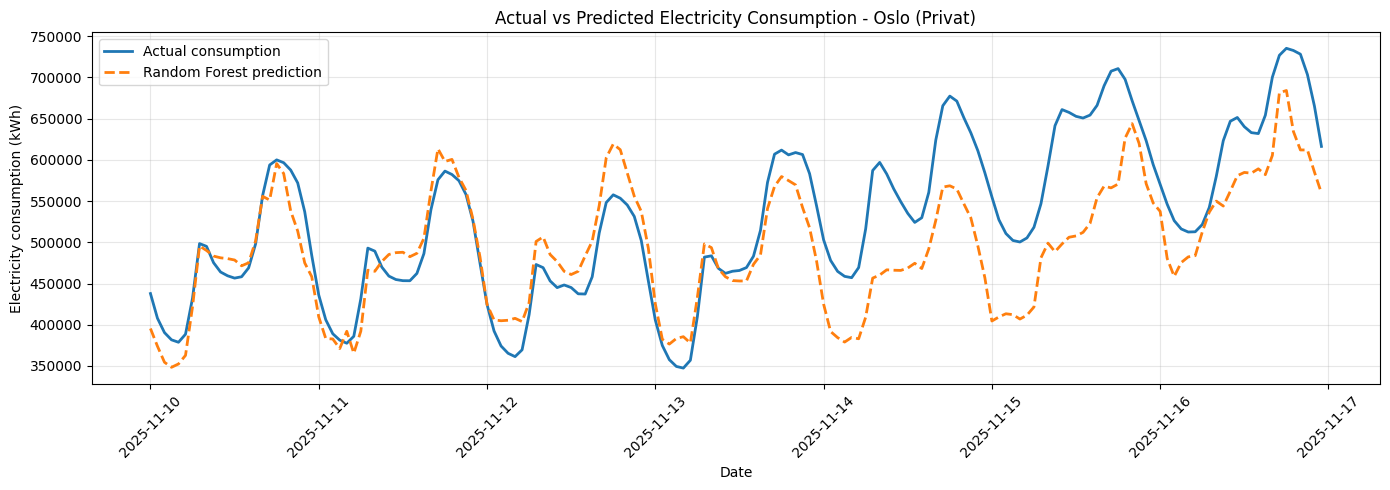

In [29]:
import matplotlib.pyplot as plt

# Bruk valideringsdataene og Random Forest-prediksjonene
plot_df = validation.copy()
plot_df["PRED_RF_B"] = pred_rf_B

# Velg kommune, forbruksgruppe og periode
subset = plot_df[
    (plot_df["KOMMUNE"] == "Oslo") &
    (plot_df["FORBRUKSGRUPPE"] == "Privat") &
    (plot_df["DATE_KEY"] >= "2025-11-10") &
    (plot_df["DATE_KEY"] < "2025-11-17")
].sort_values("TIMESTAMP")

# Plot
plt.figure(figsize=(14, 5))

plt.plot(
    subset["TIMESTAMP"],
    subset["VOLUM_KWH"],
    label="Actual consumption",
    linewidth=2
)

plt.plot(
    subset["TIMESTAMP"],
    subset["PRED_RF_B"],
    label="Random Forest prediction",
    linewidth=2,
    linestyle="--"
)

plt.title("Actual vs Predicted Electricity Consumption - Oslo (Privat)")
plt.xlabel("Date")
plt.ylabel("Electricity consumption (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Beregning av residualene

In [30]:

# Lag datasett for residualanalyse
residual_df = validation.copy()

# Legg til prediksjoner
residual_df["PREDICTED"] = pred_rf_B

# Beregn residualer
residual_df["RESIDUAL"] = (
    residual_df["VOLUM_KWH"] - residual_df["PREDICTED"]
)

print(residual_df["RESIDUAL"].describe())


count    262740.000000
mean       -229.154073
std       14689.903926
min     -486939.552099
25%       -2439.921892
50%         -62.348329
75%        2093.698434
max      344345.766441
Name: RESIDUAL, dtype: float64


Visualisering av residualene

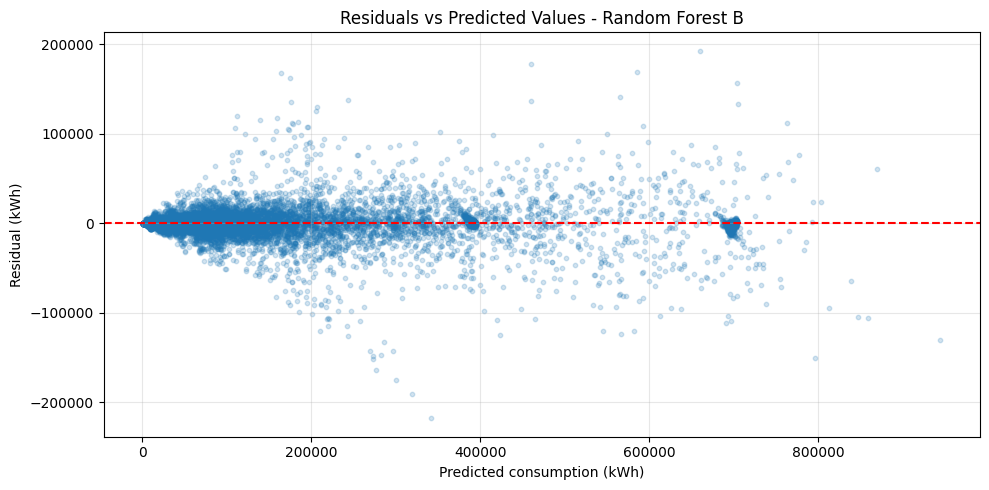

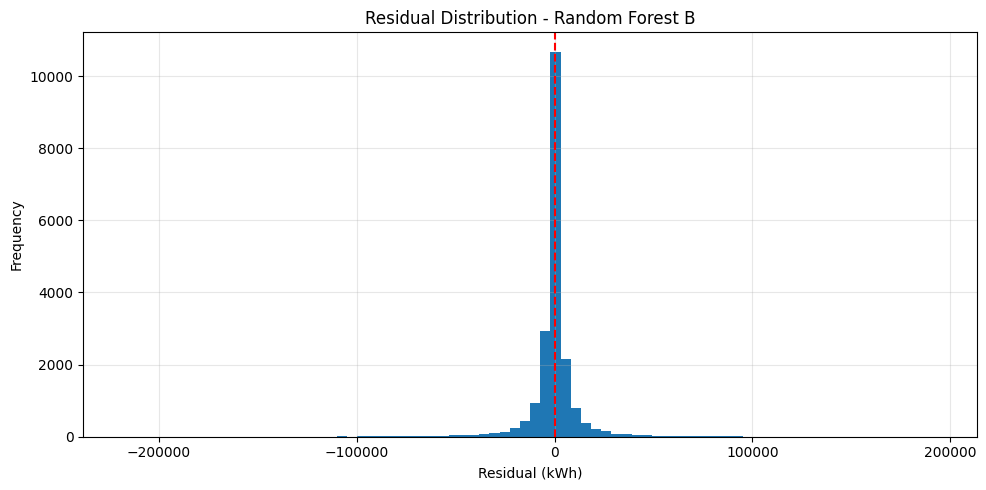

In [31]:
import matplotlib.pyplot as plt

# Tilfeldig utvalg for plotting
sample_residuals = residual_df.sample(
    n=min(20000, len(residual_df)),
    random_state=42
)

# Residualer mot predikert forbruk
plt.figure(figsize=(10, 5))

plt.scatter(
    sample_residuals["PREDICTED"],
    sample_residuals["RESIDUAL"],
    alpha=0.2,
    s=10
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted consumption (kWh)")
plt.ylabel("Residual (kWh)")
plt.title("Residuals vs Predicted Values - Random Forest B")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Fordelingen av residualene
plt.figure(figsize=(10, 5))

plt.hist(
    sample_residuals["RESIDUAL"],
    bins=80
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Residual (kWh)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Random Forest B")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Kontrollering av historiske prediktorer

In [32]:
# Kontroller de historiske prediktorene for 1000 tilfeldige rader
sample_check = validation.sample(
    n=1000,
    random_state=42
)

errors = []

for _, row in sample_check.iterrows():
    for days, feature in [
        (2, "LAG_2D"),
        (7, "LAG_7D")
    ]:
        historical = df[
            (df["KOMMUNE"] == row["KOMMUNE"]) &
            (df["FORBRUKSGRUPPE"] == row["FORBRUKSGRUPPE"]) &
            (df["DATE_KEY"] == row["DATE_KEY"] - pd.Timedelta(days=days)) &
            (df["LOCAL_HOUR"] == row["LOCAL_HOUR"])
        ]

        if len(historical) > 0:
            expected = historical["VOLUM_KWH"].mean()

            if not np.isclose(
                row[feature],
                expected,
                rtol=1e-9,
                atol=1e-6
            ):
                errors.append({
                    "Feature": feature,
                    "Date": row["DATE_KEY"],
                    "Expected": expected,
                    "Actual": row[feature]
                })

print("Antall avvik:", len(errors))
print(pd.DataFrame(errors).head())


Antall avvik: 0
Empty DataFrame
Columns: []
Index: []


Kontroll av PREV_DAY_MEAN

In [33]:
# Kontroller PREV_DAY_MEAN
sample_check = validation.sample(
    n=1000,
    random_state=42
)

errors = []

for _, row in sample_check.iterrows():

    previous_date = (
        row["DATE_KEY"] - pd.Timedelta(days=2)
    )

    historical = df[
        (df["KOMMUNE"] == row["KOMMUNE"]) &
        (df["FORBRUKSGRUPPE"] == row["FORBRUKSGRUPPE"]) &
        (df["DATE_KEY"] == previous_date)
    ]

    if len(historical) == 0:
        errors.append("Missing historical data")
        continue

    expected = historical["VOLUM_KWH"].mean()
    actual = row["PREV_DAY_MEAN"]

    if not np.isclose(
        expected,
        actual,
        rtol=1e-9,
        atol=1e-6
    ):
        errors.append({
            "Date": row["DATE_KEY"],
            "Expected": expected,
            "Actual": actual
        })

print("Antall avvik:", len(errors))
print(pd.DataFrame(errors).head())


Antall avvik: 0
Empty DataFrame
Columns: []
Index: []


Kontroll av data leakage

In [34]:
# Kontroller historiske tidsgrenser
check = df_model.copy()

# Prognosetidspunkt for hver observasjon
check["FORECAST_TIME"] = check["DATE_KEY"] - pd.Timedelta(days=1)

# Tidspunkt for de historiske observasjonene
check["LAG_2D_TIME"] = (
    check["DATE_KEY"] - pd.Timedelta(days=2)
)

check["LAG_7D_TIME"] = (
    check["DATE_KEY"] - pd.Timedelta(days=7)
)

# Kontroll: historiske datoer skal være før prognosetidspunktet
invalid_2d = (
    check["LAG_2D_TIME"] >= check["FORECAST_TIME"]
).sum()

invalid_7d = (
    check["LAG_7D_TIME"] >= check["FORECAST_TIME"]
).sum()

print("Ugyldige LAG_2D:", invalid_2d)
print("Ugyldige LAG_7D:", invalid_7d)


Ugyldige LAG_2D: 0
Ugyldige LAG_7D: 0


Kontroll av SLUTTID

In [ ]:
# Kontroller tidsgrensene for historiske inputvariabler.
# Publiseringsforsinkelsen er en antakelse, ikke dokumentert her.
publication_delay = pd.Timedelta(hours=1)

check = df_model[
    keys + ["DATE_KEY", "LOCAL_HOUR"]
].copy()

# Trekk fra ett kalenderdøgn før tidssonen settes.
check["FORECAST_TIME"] = (
    (check["DATE_KEY"] - pd.Timedelta(days=1))
    .dt.tz_localize("Europe/Oslo")
    .dt.tz_convert("UTC")
)

history = df[
    keys + ["DATE_KEY", "LOCAL_HOUR", "SLUTTID", "VOLUM_KWH"]
].copy()

history["MEASUREMENT_END"] = pd.to_datetime(
    history["SLUTTID"], utc=True
)

# Bare målinger som faktisk kan bidra til de historiske verdiene.
history = history.dropna(subset=["VOLUM_KWH"])

results = []

for feature, days, hourly in [
    ("LAG_2D", 2, True),
    ("LAG_7D", 7, True),
    ("PREV_DAY_MEAN", 2, False),
]:
    join_keys = keys + ["DATE_KEY"]
    if hourly:
        join_keys = join_keys + ["LOCAL_HOUR"]

    # Ved gjentatt time brukes siste intervallslutt.
    # For døgnmiddel brukes siste intervallslutt i hele døgnet.
    lookup = (
        history.groupby(join_keys)["MEASUREMENT_END"]
        .max()
        .reset_index()
    )
    lookup["DATE_KEY"] += pd.Timedelta(days=days)

    audit = check.merge(
        lookup,
        on=join_keys,
        how="left",
        validate="many_to_one",
    )

    assumed_available = (
        audit["MEASUREMENT_END"] + publication_delay
    )

    results.append({
        "Variabel": feature,
        "Mangler sluttid": assumed_available.isna().sum(),
        "Etter prognosetidspunkt": (
            assumed_available > audit["FORECAST_TIME"]
        ).sum(),
        "Akkurat ved prognosetidspunkt": (
            assumed_available == audit["FORECAST_TIME"]
        ).sum(),
    })

availability_results = pd.DataFrame(results)
print(availability_results.to_string(index=False))

     Variabel  Mangler sluttid  Etter prognosetidspunkt  Akkurat ved prognosetidspunkt
       LAG_2D                0                    46290                          46290
       LAG_7D                0                        0                              0
PREV_DAY_MEAN                0                  1110630                              0


Test ut ulike hyperparametere

In [36]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
import pandas as pd

# Hyperparametere vi vil undersøke
parameter_sets = [
    {"max_depth": 10, "min_samples_leaf": 5},
    {"max_depth": 15, "min_samples_leaf": 5},
    {"max_depth": 20, "min_samples_leaf": 5},
    {"max_depth": 20, "min_samples_leaf": 10},
    {"max_depth": None, "min_samples_leaf": 10}
]

rf_tuning_results = []

for params in parameter_sets:

    model = Pipeline([
        ("preprocessing", clone(rf_preprocessor_B)),
        ("regression", RandomForestRegressor(
            n_estimators=100,
            max_depth=params["max_depth"],
            min_samples_leaf=params["min_samples_leaf"],
            max_features=1.0,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train_B, y_train)
    predictions = model.predict(X_val_B)

    mae = mean_absolute_error(y_val, predictions)

    rf_tuning_results.append({
        "max_depth": params["max_depth"],
        "min_samples_leaf": params["min_samples_leaf"],
        "MAE": mae
    })

    print(params, "MAE:", round(mae, 2))

rf_tuning_results = pd.DataFrame(rf_tuning_results)

print("\nResultater:")
print(
    rf_tuning_results
    .sort_values("MAE")
    .round(2)
    .to_string(index=False)
)


{'max_depth': 10, 'min_samples_leaf': 5} MAE: 6910.08
{'max_depth': 15, 'min_samples_leaf': 5} MAE: 6466.85
{'max_depth': 20, 'min_samples_leaf': 5} MAE: 6408.93
{'max_depth': 20, 'min_samples_leaf': 10} MAE: 6421.17
{'max_depth': None, 'min_samples_leaf': 10} MAE: 6422.39

Resultater:
 max_depth  min_samples_leaf     MAE
      20.0                 5 6408.93
      20.0                10 6421.17
       NaN                10 6422.39
      15.0                 5 6466.85
      10.0                 5 6910.08


Optimalisere Gradient Boosting B

In [37]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import pandas as pd

parameter_sets_gb = [
    {"max_iter": 100, "learning_rate": 0.1, "max_leaf_nodes": 31},
    {"max_iter": 200, "learning_rate": 0.1, "max_leaf_nodes": 31},
    {"max_iter": 300, "learning_rate": 0.1, "max_leaf_nodes": 31},
    {"max_iter": 300, "learning_rate": 0.05, "max_leaf_nodes": 31},
    {"max_iter": 300, "learning_rate": 0.1, "max_leaf_nodes": 63}
]

gb_tuning_results = []

for params in parameter_sets_gb:

    model = Pipeline([
        ("preprocessing", clone(gb_preprocessor_B)),
        ("regression", HistGradientBoostingRegressor(
            **params,
            random_state=42
        ))
    ])

    model.fit(X_train_B, y_train)
    predictions = model.predict(X_val_B)

    mae = mean_absolute_error(y_val, predictions)

    gb_tuning_results.append({
        **params,
        "MAE": mae
    })

    print(params, "MAE:", round(mae, 2))

gb_tuning_results = pd.DataFrame(gb_tuning_results)

print("\nResultater:")
print(
    gb_tuning_results
    .sort_values("MAE")
    .round(2)
    .to_string(index=False)
)


{'max_iter': 100, 'learning_rate': 0.1, 'max_leaf_nodes': 31} MAE: 6826.37
{'max_iter': 200, 'learning_rate': 0.1, 'max_leaf_nodes': 31} MAE: 6642.32
{'max_iter': 300, 'learning_rate': 0.1, 'max_leaf_nodes': 31} MAE: 6519.71
{'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 31} MAE: 6707.49
{'max_iter': 300, 'learning_rate': 0.1, 'max_leaf_nodes': 63} MAE: 6329.38

Resultater:
 max_iter  learning_rate  max_leaf_nodes     MAE
      300           0.10              63 6329.38
      300           0.10              31 6519.71
      200           0.10              31 6642.32
      300           0.05              31 6707.49
      100           0.10              31 6826.37


Kontroller av de to beste modellene

In [38]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Beste Random Forest
best_rf = Pipeline([
    ("preprocessing", clone(rf_preprocessor_B)),
    ("regression", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

# Beste Gradient Boosting
best_gb = Pipeline([
    ("preprocessing", clone(gb_preprocessor_B)),
    ("regression", HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.1,
        max_leaf_nodes=63,
        random_state=42
    ))
])

# Tren på 2022–2024
best_rf.fit(X_train_B, y_train)
best_gb.fit(X_train_B, y_train)

# Prediker 2025
pred_best_rf = best_rf.predict(X_val_B)
pred_best_gb = best_gb.predict(X_val_B)

# Sammenlign
final_validation = pd.DataFrame({
    "Model": ["Random Forest B", "Gradient Boosting B"],
    "MAE": [
        mean_absolute_error(y_val, pred_best_rf),
        mean_absolute_error(y_val, pred_best_gb)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, pred_best_rf)),
        np.sqrt(mean_squared_error(y_val, pred_best_gb))
    ],
    "R2": [
        r2_score(y_val, pred_best_rf),
        r2_score(y_val, pred_best_gb)
    ]
})

print(final_validation.round(3).to_string(index=False))

              Model      MAE      RMSE    R2
    Random Forest B 6408.926 14689.193 0.992
Gradient Boosting B 6329.376 14568.050 0.992


In [52]:
from sklearn.base import clone

# Kalenderbasert preprocessing:
# samme behandling som B, men uten historiske forbruksvariabler.
gb_preprocessor_A = ColumnTransformer([
    ("num", "passthrough", numerical_A),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    ), categorical_features),
])

# To separate modeller med identiske modellinnstillinger
gb_comparison_A = clone(best_gb).set_params(
    preprocessing=gb_preprocessor_A,
    regression__early_stopping=False,
)

gb_comparison_B = clone(best_gb).set_params(
    regression__early_stopping=False,
)

# Kontroller at modellene bruker nøyaktig de samme radene
assert X_train_A.index.equals(X_train_B.index)
assert X_val_A.index.equals(X_val_B.index)
assert X_train_A.index.equals(y_train.index)
assert X_val_A.index.equals(y_val.index)

# Tren på 2022–2024
gb_comparison_A.fit(X_train_A, y_train)
gb_comparison_B.fit(X_train_B, y_train)

# Evaluer på de samme valideringsradene fra 2025
pred_gb_comparison_A = gb_comparison_A.predict(X_val_A)
pred_gb_comparison_B = gb_comparison_B.predict(X_val_B)

comparison_results = []

for name, model, predictions in [
    ("Gradient Boosting A", gb_comparison_A, pred_gb_comparison_A),
    ("Gradient Boosting B", gb_comparison_B, pred_gb_comparison_B),
]:
    comparison_results.append({
        "Modell": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "Iterasjoner": model.named_steps["regression"].n_iter_,
    })

gb_AB_results = pd.DataFrame(comparison_results)
print(gb_AB_results.round(2).to_string(index=False))

mae_A = gb_AB_results.loc[0, "MAE"]
mae_B = gb_AB_results.loc[1, "MAE"]

print(f"\nReduksjon i MAE med historikk: {mae_A - mae_B:,.2f} kWh")

if mae_A > 0:
    improvement = 100 * (mae_A - mae_B) / mae_A
    print(f"Relativ forbedring fra A til B: {improvement:.2f} %")

             Modell     MAE     RMSE  Iterasjoner
Gradient Boosting A 9127.27 18565.59          300
Gradient Boosting B 6369.10 14724.98          300

Reduksjon i MAE med historikk: 2,758.17 kWh
Relativ forbedring fra A til B: 30.22 %


Trene endelig modell

In [39]:
from sklearn.base import clone

# Kombiner train og validation
X_train_final = pd.concat(
    [X_train_B, X_val_B],
    axis=0
)

y_train_final = pd.concat(
    [y_train, y_val],
    axis=0
)

# Endelig modell med valgte hyperparametere
final_model = clone(best_gb)

# Tren på 2022–2025
final_model.fit(X_train_final, y_train_final)

print("Endelig Gradient Boosting-modell ferdig trent.")
print("Antall treningsobservasjoner:", len(X_train_final))


Endelig Gradient Boosting-modell ferdig trent.
Antall treningsobservasjoner: 1024320


In [48]:
import sklearn

print("scikit-learn-versjon:", sklearn.__version__)

results = []

for name, pipeline in [
    ("Gradient Boosting B", gb_B),
    ("Beste Gradient Boosting B", best_gb),
    ("Endelig modell", final_model),
]:
    model = pipeline.named_steps["regression"]

    results.append({
        "Modell": name,
        "early_stopping": model.early_stopping,
        "Early stopping aktivert": model.do_early_stopping_,
        "Valideringsandel": model.validation_fraction,
        "Maks iterasjoner": model.max_iter,
        "Faktiske iterasjoner": model.n_iter_,
        "Stoppet før maks": model.n_iter_ < model.max_iter,
        "Interne valideringsscore": len(model.validation_score_),
    })

print(pd.DataFrame(results).to_string(index=False))

scikit-learn-versjon: 1.8.0
                   Modell early_stopping  Early stopping aktivert  Valideringsandel  Maks iterasjoner  Faktiske iterasjoner  Stoppet før maks  Interne valideringsscore
      Gradient Boosting B           auto                     True               0.1               200                   200             False                       201
Beste Gradient Boosting B           auto                     True               0.1               300                   300             False                       301
           Endelig modell           auto                     True               0.1               300                   300             False                       301


Evaluering av testdataene

In [40]:
# Prediker testperioden fra 2026
pred_test = final_model.predict(X_test_B)

# Evaluer
test_mae = mean_absolute_error(y_test, pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))
test_r2 = r2_score(y_test, pred_test)

print("FINAL TEST RESULTS (2026)")
print(f"MAE: {test_mae:,.3f} kWh")
print(f"RMSE: {test_rmse:,.3f} kWh")
print(f"R2: {test_r2:.4f}")


FINAL TEST RESULTS (2026)
MAE: 8,678.351 kWh
RMSE: 19,703.980 kWh
R2: 0.9890


Gjennomsnittlig residual (kWh): 1079.39
Median residual (kWh): -58.99
Andel underprediksjoner (%): 48.92
Andel overprediksjoner (%): 51.08

Feil etter forbruksnivå, fra lavest til høyest:
                          Antall  Gjennomsnittsforbruk  Gjennomsnittlig_residual       MAE
CONSUMPTION_LEVEL                                                                         
(1552.825, 21510.306]      21578               9171.52                   -306.70   1112.43
(21510.306, 71851.88]      21577              43461.31                  -1035.50   4297.57
(71851.88, 161094.674]     21577             106194.71                  -1487.98   8576.74
(161094.674, 1073136.78]   21578             409539.83                   7147.53  20726.45


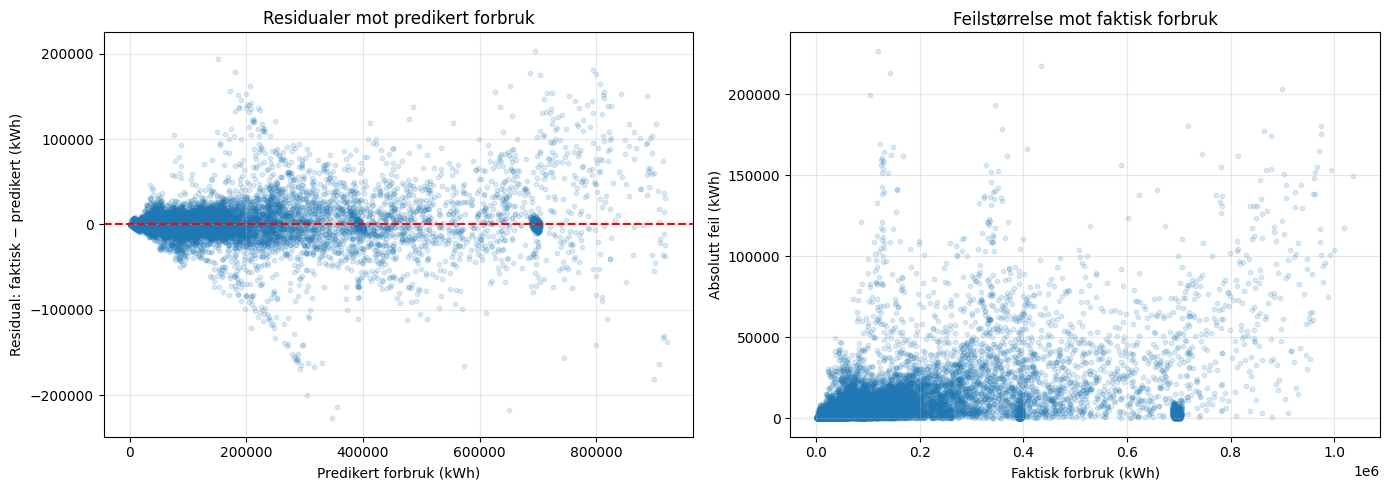

In [49]:
import matplotlib.pyplot as plt

# Faktisk og predikert forbruk i samme rekkefølge
gb_residuals = test[
    ["KOMMUNE", "FORBRUKSGRUPPE", "VOLUM_KWH"]
].copy()

gb_residuals["PREDICTED"] = pred_test

# Positiv residual = modellen underpredikerer
gb_residuals["RESIDUAL"] = (
    gb_residuals["VOLUM_KWH"] - gb_residuals["PREDICTED"]
)
gb_residuals["ABS_ERROR"] = gb_residuals["RESIDUAL"].abs()

print("Gjennomsnittlig residual (kWh):",
      round(gb_residuals["RESIDUAL"].mean(), 2))
print("Median residual (kWh):",
      round(gb_residuals["RESIDUAL"].median(), 2))
print("Andel underprediksjoner (%):",
      round(100 * (gb_residuals["RESIDUAL"] > 0).mean(), 2))
print("Andel overprediksjoner (%):",
      round(100 * (gb_residuals["RESIDUAL"] < 0).mean(), 2))

# Sammenlign feil ved ulike nivåer av faktisk forbruk
gb_residuals["CONSUMPTION_LEVEL"] = pd.qcut(
    gb_residuals["VOLUM_KWH"],
    q=4,
    duplicates="drop",
)

error_by_level = (
    gb_residuals.groupby("CONSUMPTION_LEVEL", observed=True)
    .agg(
        Antall=("RESIDUAL", "size"),
        Gjennomsnittsforbruk=("VOLUM_KWH", "mean"),
        Gjennomsnittlig_residual=("RESIDUAL", "mean"),
        MAE=("ABS_ERROR", "mean"),
    )
)

print("\nFeil etter forbruksnivå, fra lavest til høyest:")
print(error_by_level.round(2).to_string())

# Et utvalg gjør figurene lettere å lese
plot_sample = gb_residuals.sample(
    n=min(20000, len(gb_residuals)),
    random_state=42,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    plot_sample["PREDICTED"],
    plot_sample["RESIDUAL"],
    alpha=0.15,
    s=10,
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predikert forbruk (kWh)")
axes[0].set_ylabel("Residual: faktisk − predikert (kWh)")
axes[0].set_title("Residualer mot predikert forbruk")

axes[1].scatter(
    plot_sample["VOLUM_KWH"],
    plot_sample["ABS_ERROR"],
    alpha=0.15,
    s=10,
)
axes[1].set_xlabel("Faktisk forbruk (kWh)")
axes[1].set_ylabel("Absolutt feil (kWh)")
axes[1].set_title("Feilstørrelse mot faktisk forbruk")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Evaluering av forbruksgruppe

In [41]:
# Lag evalueringsdatasett
test_eval = test.copy()
test_eval["PREDICTED"] = pred_test

# Resultater per forbruksgruppe
group_test_results = []

for group, subset in test_eval.groupby("FORBRUKSGRUPPE"):
    actual = subset["VOLUM_KWH"]
    predicted = subset["PREDICTED"]

    group_test_results.append({
        "Group": group,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

group_test_results = pd.DataFrame(group_test_results)

print(group_test_results.round(3).to_string(index=False))


     Group       MAE      RMSE    R2
Forretning  5689.959 11716.367 0.993
  Industri  8268.975 21563.706 0.990
    Privat 12076.119 23716.529 0.985


Eval av koummne

In [42]:
municipality_test_results = []

for municipality, subset in test_eval.groupby("KOMMUNE"):
    actual = subset["VOLUM_KWH"]
    predicted = subset["PREDICTED"]

    municipality_test_results.append({
        "Kommune": municipality,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

municipality_test_results = pd.DataFrame(municipality_test_results)

print(
    municipality_test_results
    .sort_values("MAE", ascending=False)
    .round(3)
    .to_string(index=False)
)


     Kommune       MAE      RMSE    R2
        Oslo 38952.717 54470.801 0.948
      Bergen 13313.864 19380.933 0.974
   Trondheim 11434.122 15637.749 0.954
   Stavanger  6017.408  8774.552 0.974
Kristiansand  5574.325  8174.542 0.938
      Tromsø  3483.338  4843.813 0.983
        Bodø  2659.311  3782.902 0.978
        Alta  2216.271  3005.300 0.939
     Sunndal  1783.538  8626.164 0.999
       Årdal  1348.616  5496.264 0.999


Baseline vs. Gradient boosting på baseline

In [43]:
# Historisk baseline på testdataene
baseline_test = test["LAG_7D"]

# Beregn evalueringsmetrikker
test_comparison = pd.DataFrame({
    "Model": [
        "Historical Baseline",
        "Gradient Boosting B"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_test),
        mean_absolute_error(y_test, pred_test)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_test)),
        np.sqrt(mean_squared_error(y_test, pred_test))
    ],
    "R2": [
        r2_score(y_test, baseline_test),
        r2_score(y_test, pred_test)
    ]
})

print(test_comparison.round(3).to_string(index=False))


              Model       MAE      RMSE    R2
Historical Baseline 12622.610 28645.349 0.977
Gradient Boosting B  8678.351 19703.980 0.989


Normalisert MAE per kommune

In [44]:
# Normalisert MAE per kommune
relative_results = []

for municipality, subset in test_eval.groupby("KOMMUNE"):

    actual = subset["VOLUM_KWH"]
    predicted = subset["PREDICTED"]

    mae = mean_absolute_error(actual, predicted)
    mean_consumption = actual.abs().mean()

    nmae = (mae / mean_consumption) * 100

    relative_results.append({
        "Kommune": municipality,
        "MAE_kWh": mae,
        "Mean_Consumption_kWh": mean_consumption,
        "NMAE_%": nmae
    })

relative_results = pd.DataFrame(relative_results)

print(
    relative_results
    .sort_values("NMAE_%", ascending=False)
    .round(2)
    .to_string(index=False)
)


     Kommune  MAE_kWh  Mean_Consumption_kWh  NMAE_%
        Alta  2216.27              22774.38    9.73
        Oslo 38952.72             430532.90    9.05
   Trondheim 11434.12             133220.25    8.58
      Bergen 13313.86             177482.63    7.50
        Bodø  2659.31              38865.47    6.84
   Stavanger  6017.41              97512.82    6.17
Kristiansand  5574.32              90480.96    6.16
      Tromsø  3483.34              59697.19    5.84
       Årdal  1348.62             134293.75    1.00
     Sunndal  1783.54             236073.68    0.76


NMAE per kommune og forbruksgruppe

In [45]:
# Normalisert MAE per kommune og forbruksgruppe
detailed_results = []

for (municipality, group), subset in test_eval.groupby(
    ["KOMMUNE", "FORBRUKSGRUPPE"]
):
    actual = subset["VOLUM_KWH"]
    predicted = subset["PREDICTED"]

    mae = mean_absolute_error(actual, predicted)
    mean_consumption = actual.abs().mean()

    nmae = (
        100 * mae / mean_consumption
        if mean_consumption > 0 else np.nan
    )

    detailed_results.append({
        "Kommune": municipality,
        "Forbruksgruppe": group,
        "MAE_kWh": mae,
        "Mean_Consumption_kWh": mean_consumption,
        "NMAE_%": nmae
    })

detailed_results = pd.DataFrame(detailed_results)

print(
    detailed_results
    .sort_values(["Kommune", "Forbruksgruppe"])
    .round(2)
    .to_string(index=False)
)


     Kommune Forbruksgruppe  MAE_kWh  Mean_Consumption_kWh  NMAE_%
        Alta     Forretning  2106.79              21753.90    9.68
        Alta       Industri  1250.99              10711.61   11.68
        Alta         Privat  3291.04              35857.63    9.18
      Bergen     Forretning 11655.59             188379.66    6.19
      Bergen       Industri  6185.56              36870.58   16.78
      Bergen         Privat 22100.44             307197.66    7.19
        Bodø     Forretning  2168.78              38372.57    5.65
        Bodø       Industri  1627.28              10583.39   15.38
        Bodø         Privat  4181.87              67640.45    6.18
Kristiansand     Forretning  3764.66              57810.30    6.51
Kristiansand       Industri  4410.92              92145.01    4.79
Kristiansand         Privat  8547.40             121487.58    7.04
        Oslo     Forretning 21911.98             471411.14    4.65
        Oslo       Industri 45790.08             172195.75   2

In [50]:
comparison_rows = []

for (municipality, group), subset in test_eval.groupby(
    ["KOMMUNE", "FORBRUKSGRUPPE"]
):
    actual = subset["VOLUM_KWH"]

    mae_model = mean_absolute_error(
        actual, subset["PREDICTED"]
    )
    mae_baseline = mean_absolute_error(
        actual, subset["LAG_7D"]
    )

    improvement = (
        100 * (mae_baseline - mae_model) / mae_baseline
        if mae_baseline > 0 else np.nan
    )

    comparison_rows.append({
        "Kommune": municipality,
        "Forbruksgruppe": group,
        "MAE_modell": mae_model,
        "MAE_baseline": mae_baseline,
        "Forbedring_prosent": improvement,
    })

baseline_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("Forbedring_prosent", ascending=False)
)

print("Alle kombinasjoner, sortert etter relativ forbedring:")
print(baseline_comparison.round(2).to_string(index=False))

print("\nDe fem største relative forbedringene:")
print(baseline_comparison.head(5).round(2).to_string(index=False))

worse = baseline_comparison[
    baseline_comparison["MAE_modell"]
    > baseline_comparison["MAE_baseline"]
]

print(f"\nAntall kombinasjoner dårligere enn baseline: {len(worse)}")

if worse.empty:
    print("Ingen kombinasjoner har høyere MAE enn baseline.")
else:
    print(
        worse.sort_values("Forbedring_prosent")
        .round(2)
        .to_string(index=False)
    )

Alle kombinasjoner, sortert etter relativ forbedring:
     Kommune Forbruksgruppe  MAE_modell  MAE_baseline  Forbedring_prosent
      Tromsø         Privat     5448.00       9890.81               44.92
        Bodø         Privat     4181.87       7268.32               42.46
   Stavanger         Privat    10047.78      17456.80               42.44
      Bergen         Privat    22100.44      37514.85               41.09
   Trondheim         Privat    16463.96      27441.94               40.00
      Tromsø     Forretning     2933.07       4773.78               38.56
   Stavanger     Forretning     5301.17       8283.81               36.01
        Oslo     Forretning    21911.98      34171.71               35.88
        Alta         Privat     3291.04       5091.40               35.36
Kristiansand         Privat     8547.40      13217.61               35.33
        Bodø       Industri     1627.28       2512.34               35.23
      Bergen     Forretning    11655.59      17767.87     

In [51]:
monthly_rows = []

for period, data, predictions in [
    ("Validering", validation, pred_best_gb),
    ("Uavhengig test", test, pred_test),
]:
    monthly_data = data[
        ["TIMESTAMP", "VOLUM_KWH", "LAG_7D"]
    ].copy()

    monthly_data["PREDICTED"] = predictions
    monthly_data["MONTH"] = (
        monthly_data["TIMESTAMP"].dt.strftime("%Y-%m")
    )

    for month, subset in monthly_data.groupby("MONTH"):
        actual = subset["VOLUM_KWH"]

        mae_model = mean_absolute_error(
            actual, subset["PREDICTED"]
        )
        mae_baseline = mean_absolute_error(
            actual, subset["LAG_7D"]
        )

        monthly_rows.append({
            "Periode": period,
            "Måned": month,
            "Antall": len(subset),
            "MAE_modell": mae_model,
            "MAE_baseline": mae_baseline,
            "Forbedring_prosent": (
                100 * (mae_baseline - mae_model) / mae_baseline
                if mae_baseline > 0 else np.nan
            ),
        })

monthly_results = pd.DataFrame(monthly_rows)

# Vis validering og test hver for seg
for period in ["Validering", "Uavhengig test"]:
    result = (
        monthly_results[monthly_results["Periode"] == period]
        .sort_values("Måned")
    )

    print(f"\n{period.upper()}")
    print(result.round(2).to_string(index=False))

    valid = result.dropna(subset=["Forbedring_prosent"])

    if not valid.empty:
        best = valid.loc[valid["Forbedring_prosent"].idxmax()]
        worst = valid.loc[valid["Forbedring_prosent"].idxmin()]

        print(
            f"\nStørst relativ forbedring: {best['Måned']} "
            f"({best['Forbedring_prosent']:.2f} %)"
        )
        print(
            f"Minst relativ forbedring: {worst['Måned']} "
            f"({worst['Forbedring_prosent']:.2f} %)"
        )


VALIDERING
   Periode   Måned  Antall  MAE_modell  MAE_baseline  Forbedring_prosent
Validering 2025-01   22320    10961.28      18464.30               40.64
Validering 2025-02   20160     9646.62      12962.47               25.58
Validering 2025-03   22290     7311.51      11449.74               36.14
Validering 2025-04   21540     7154.22      10382.45               31.09
Validering 2025-05   22320     5536.03       7576.22               26.93
Validering 2025-06   21600     3782.56       5238.10               27.79
Validering 2025-07   22320     2618.76       3730.41               29.80
Validering 2025-08   22320     3208.64       4671.55               31.32
Validering 2025-09   21600     3560.91       5318.77               33.05
Validering 2025-10   22350     4818.97       7241.24               33.45
Validering 2025-11   21600     9257.09      13833.97               33.08
Validering 2025-12   22320     8372.09      10404.99               19.54

Størst relativ forbedring: 2025-01 (40